# PET Enzyme Explorer — Bioinformatics and Machine-Learning Analysis

**Project:** *PET Enzyme Explorer: A Bioinformatics and Machine Learning System for Identifying and Characterising
PET-Degrading Enzymes* (Computing for Bioinformatics, year 4).

This notebook documents the scientific analysis behind the dashboard (`app/streamlit_app.py`) in the order it was done.
Expensive steps (44,253 pairwise alignments, clustering grids) are cached in `outputs/explorer/`; set
`RECOMPUTE = True` below to regenerate everything from the raw files.

**Convention:** *experimentally established* = taken from PAZy assay records.
*Computational* = derived here (similarity, clusters, predictions).

## 1. Research question and hypotheses

A previous feasibility analysis (`outputs/pet_dataset_feasibility_report.md`) showed that the data contain
**298 PET-active proteins with sequences but 0 usable PET-inactive ones**, so PET-active vs PET-inactive
classification is not possible. The question is therefore descriptive and unsupervised:

> **Research question.** Do experimentally verified PET-hydrolysing enzymes form distinct groups based on their
> amino-acid sequence features, and do these groups relate to the temperatures at which PET degradation was observed?

* **H1** — Most verified PET-active enzymes belong to a small number of sequence-similarity groups that share the
  serine-hydrolase G-x-S-x-G catalytic motif.
* **H2** — Sequence groups differ in the temperatures at which PET degradation has been detected.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from pet_explorer import config as C, pipeline
pd.set_option("display.max_colwidth", 80, "display.width", 200)

RECOMPUTE = False   # True = rebuild all cached outputs (~1 min on 10 cores)
if RECOMPUTE or not (C.ORGANISMS / "protein_organisms.csv").exists():
    C.ensure_dirs(); pipeline.stage1(); pipeline.stage2();
    from pet_explorer import temperature, organisms
    temperature.run(); organisms.run(); pipeline.export_network()
fig = lambda name, w=700: display(Image(filename=str(C.FIGURES / name), width=w))

## 2. Data acquisition and provenance

Six files were downloaded by the project team into `data/` and are **never modified**:

| Source | File | Role here |
|---|---|---|
| PAZy (Plastics-Active enZymes database) | `pazy_proteins_sequences.csv`, `pazy_proteins.fasta` | Protein sequences (301) |
| PAZy | `pazy_polymer_assays.json.gz` (schema 4.2) | Experimental assays (7,195; 5,058 on PET) |
| PlasticDB | `PlasticDB.fasta`, `degraders_list.tsv` | Organism links, Tax IDs, isolation data |
| UniProt (downloaded 2026-10-27, from file name) | `uniprotkb_…fasta.gz` | Reference cutinases (3) |

Download dates of the non-UniProt files were not recorded. Licences and versions should be noted from the source websites.

In [2]:
pd.read_csv(C.FEASIBILITY / "tables/dataset_inventory.csv")[["file", "format", "records", "unique_ids", "duplicate_sequences", "notes"]]

,file,format,records,unique_ids,duplicate_sequences,notes
0,pazy_proteins_sequences.csv,CSV,301,301,0.0,Key = protein_id (integer). Only PET-tested PAZy proteins appear here.
1,pazy_polymer_assays.json.gz,gzipped JSON list,579,462,NaN,One record per protein x publication; 7195 assays in total. Key = protein_id...
2,pazy_proteins.fasta,FASTA,301,301,0.0,Same IDs/sequences as the CSV (checked in Step 4).
3,PlasticDB.fasta,FASTA,329,329,18.0,Positive associations only (no negative results). missing_values = entries w...
4,degraders_list.tsv,TSV,2535,933,214.0,Organism x plastic rows (unique_ids = unique organisms); only some rows carr...
5,uniprotkb_accession_E9LVH8_OR_accession_2026_10_27.fasta.gz,gzipped FASTA,3,3,0.0,E9LVH8 Cutinase 1 (Fragment); E9LVH9 Cutinase 2 (Fragment); Q47RJ6 Cutinase


## 3. Pre-processing and quality control

Activity labels come from the feasibility analysis (`analyze_pet_dataset.py`). Each PET assay is classified from its
measurements: degradation detected / nothing detected / unclear / excluded. These assay results are then aggregated
per protein. We keep the 298 proteins that are **PET-active (high/medium confidence) and have a valid sequence**.
Every sequence is re-checked against the raw CSV.

In [3]:
display(pd.read_csv(C.CLEAN / "qc_checks.csv"))
proteins = pd.read_csv(C.F_PROTEINS)
proteins.pet_label.value_counts()

,check,value,passed
0,Proteins selected (usable PET-active),298,True
1,Sequences identical to raw PAZy CSV,298,True
2,Sequences with only standard amino acids,298,True
3,Unique protein IDs,298,True
4,Unique sequences,298,True
5,Recorded length equals sequence length,298,True


pet_label
PET-active                          161
PET-active (condition-dependent)    137
Name: count, dtype: int64

## 4. Exploratory analysis of the sequences

,length,isoelectric_point,gravy,aromaticity,instability_index
count,298.00,298.00,298.00,298.00,298.00
mean,321.35,7.47,-0.16,0.09,34.93
std,73.82,1.66,0.13,0.01,7.24
min,178.00,4.24,-0.52,0.05,10.18
25%,262.25,6.03,-0.24,0.08,29.89
50%,297.00,7.80,-0.17,0.09,35.37
75%,396.50,8.96,-0.07,0.10,39.83
max,491.00,10.31,0.24,0.14,61.43


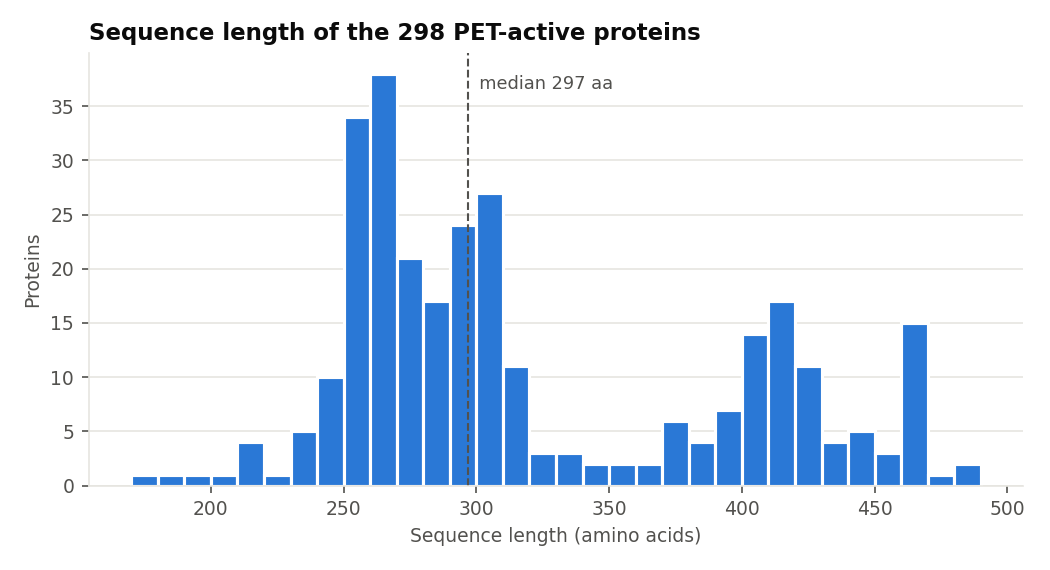

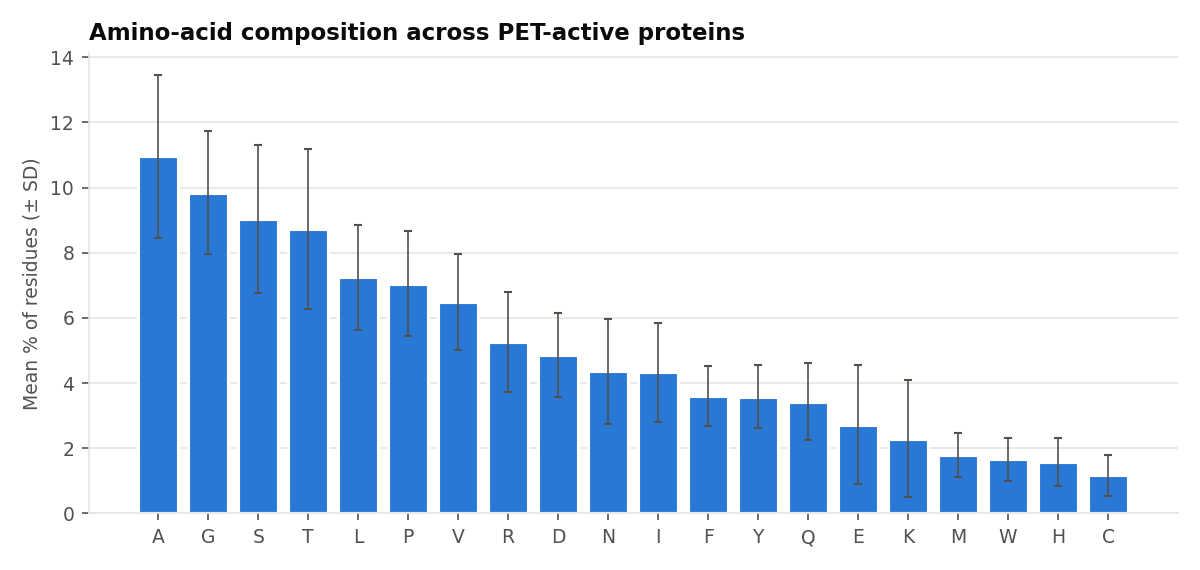

In [4]:
feats = pd.read_csv(C.CLUSTERING / "sequence_features.csv")
display(feats[["length", "isoelectric_point", "gravy", "aromaticity", "instability_index"]].describe().round(2))
fig("f01_length_distribution.png"); fig("f02_aa_composition.png")

**Interpretation.** Lengths range from 178 to 491 aa (median 297). This is consistent with single-domain α/β-hydrolases,
though several proteins are around 400–490 aa. Alanine (11.0%) and glycine (9.8%) are the most frequent residues on average. Composition
varies little between proteins, which already suggests composition alone will separate families poorly (Section 6).

### 4.1 Conserved motif

Serine hydrolases (lipases, esterases, cutinases) usually carry their catalytic serine in a **G-x-S-x-G** pentapeptide.
We search for it in every sequence (a hypothesis-driven check, not an assumption).

Proteins with >=1 G-x-S-x-G: 296 / 298


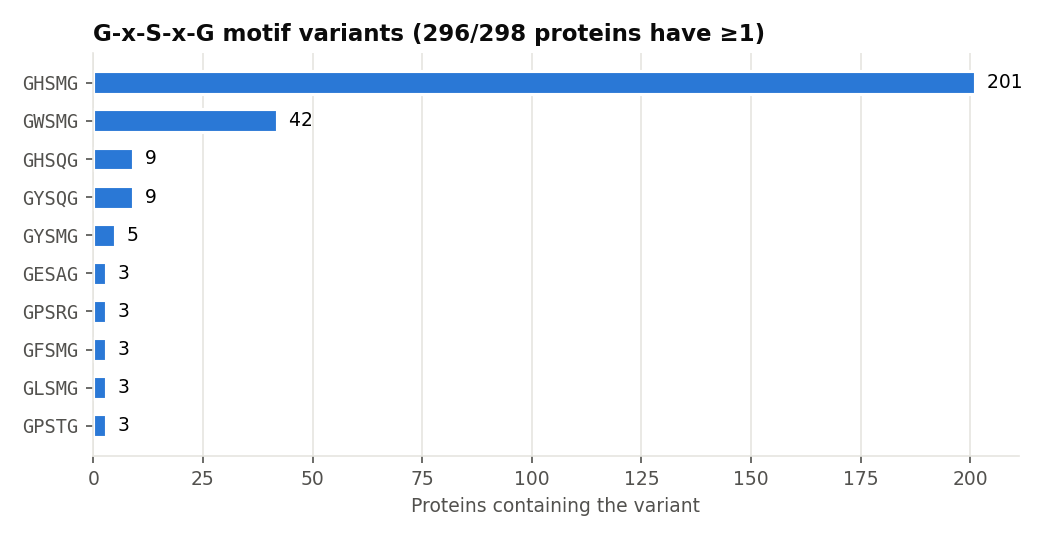

In [5]:
print("Proteins with >=1 G-x-S-x-G:", int((feats.gxsxg_count > 0).sum()), "/", len(feats))
fig("f09_gxsxg_motif_variants.png")

## 5. Pairwise sequence similarity

All 44,253 protein pairs were aligned (Smith-Waterman, BLOSUM62, gap −11/−1). For each pair we store:
* identity over aligned columns
* coverage of each protein
* **identity relative to the shorter sequence**. This is coverage-aware: a short shared fragment cannot look like
  high identity. Clustering uses distance = 1 − this value.

,identity,identity_shorter,min_coverage,normalised_score
count,44253.000,44253.000,44253.000,44253.000
mean,0.431,0.359,0.611,0.277
std,0.136,0.197,0.274,0.196
min,0.154,0.011,0.012,0.012
25%,0.314,0.185,0.476,0.070
50%,0.435,0.410,0.635,0.296
75%,0.506,0.490,0.855,0.409
max,1.000,0.996,1.000,0.997


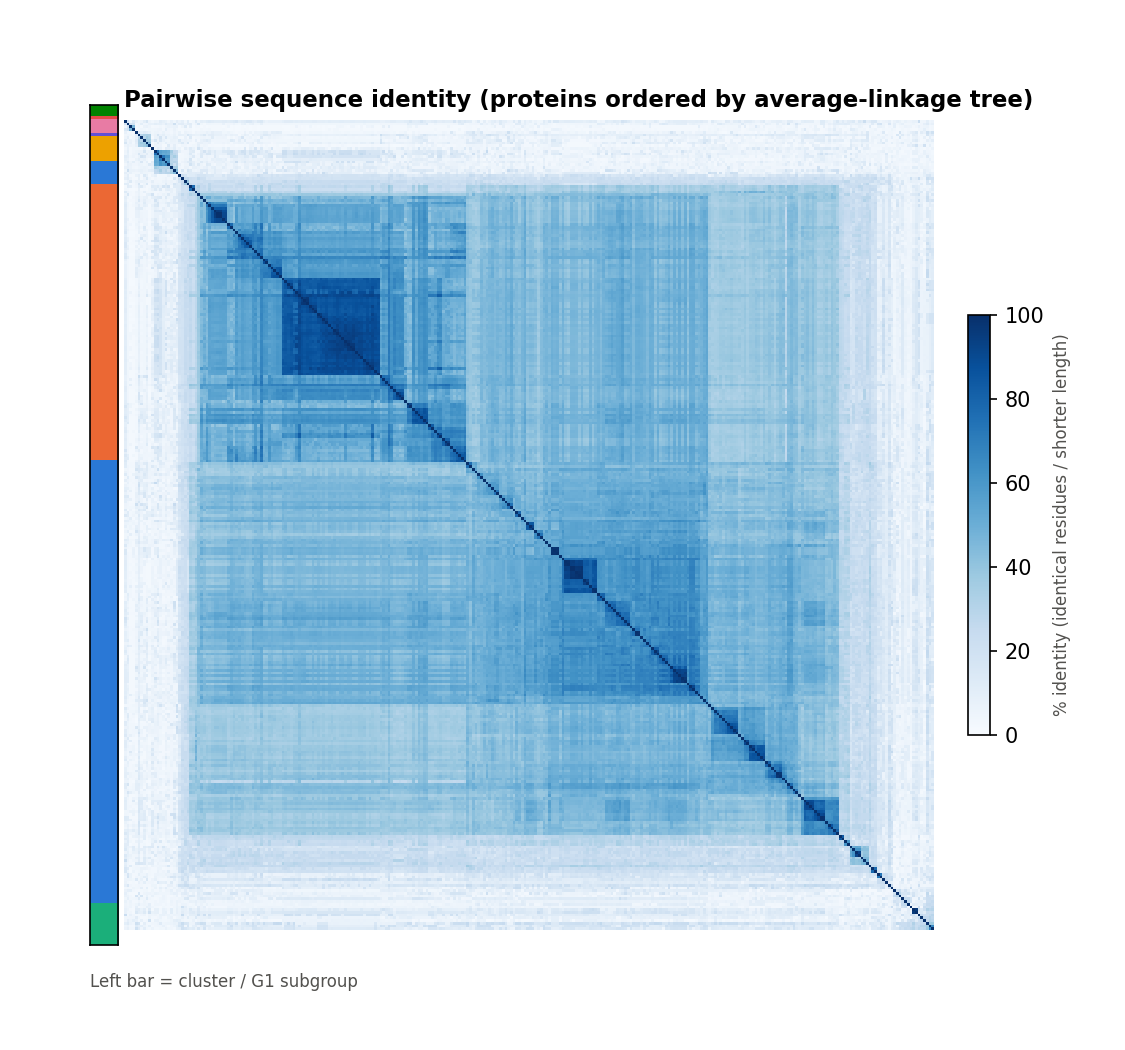

In [6]:
pairs = pd.read_csv(C.F_PAIRS)
display(pairs[["identity", "identity_shorter", "min_coverage", "normalised_score"]].describe().round(3))
fig("f07_identity_heatmap.png", 600)

**Interpretation.** The heatmap shows one very large block of moderately similar proteins (≈40–60% identity), containing
smaller, near-identical blocks (variants of the same enzyme). It also shows a few proteins that resemble almost nothing
else. This shape is why the clustering method matters.

## 6. Unsupervised machine learning: clustering

Three method families were compared on the same 298 proteins:
1. **Hierarchical clustering** (average linkage) on alignment distance, 2–80 clusters
2. **K-means** on standardised alignment-free features (20 amino-acid percentages, length, pI, GRAVY, aromaticity,
   instability, secondary-structure propensities), k = 2–30
3. **DBSCAN** on alignment distance, ε = 0.3–0.7

Each configuration was scored on the same criteria:
* silhouette on alignment distance (do groups reflect homology?)
* silhouette in feature space
* **stability**: mean adjusted Rand index (ARI) against 30 random 80% subsamples
* mean within-cluster identity
* largest-cluster share, singletons and noise

**Selection rule (fixed before inspecting cluster contents):**
* stability ≥ 0.9
* ≤ 5% unassigned
* mean within-cluster identity ≥ 40%
* then the highest alignment silhouette; ties within 0.01 go to the most stable configuration

,method,parameter,n_clusters,noise_points,singletons,largest_cluster_fraction,silhouette_alignment,silhouette_features,stability_ari_mean,stability_ari_sd,mean_within_identity,within_pairs_ge40pct
67,dbscan_alignment,0.7,4,25,0,0.849,0.377,0.199,0.986,0.016,0.459,0.722
65,dbscan_alignment,0.5,3,53,0,0.789,0.347,0.144,0.999,0.002,0.490,0.833
4,hierarchical_average_alignment,6.0,6,0,1,0.883,0.346,0.065,0.956,0.093,0.436,0.667
5,hierarchical_average_alignment,7.0,7,0,2,0.883,0.344,0.061,0.987,0.025,0.436,0.667
6,hierarchical_average_alignment,8.0,8,0,3,0.883,0.338,0.045,0.975,0.036,0.436,0.667
66,dbscan_alignment,0.6,3,46,0,0.802,0.335,0.159,0.999,0.002,0.485,0.810
50,kmeans_features,18.0,18,0,0,0.148,0.114,0.170,0.680,0.055,0.569,0.837
51,kmeans_features,19.0,19,0,0,0.121,0.106,0.168,0.666,0.050,0.576,0.822
57,kmeans_features,25.0,25,0,1,0.121,0.104,0.173,0.618,0.049,0.605,0.829


**Selected:** `hierarchical_average_alignment` with 7 clusters; ARI vs k-means (same k) = 0.08, vs DBSCAN ε=0.5 = 0.581, vs 70%-identity groups = 0.046 (110 groups).

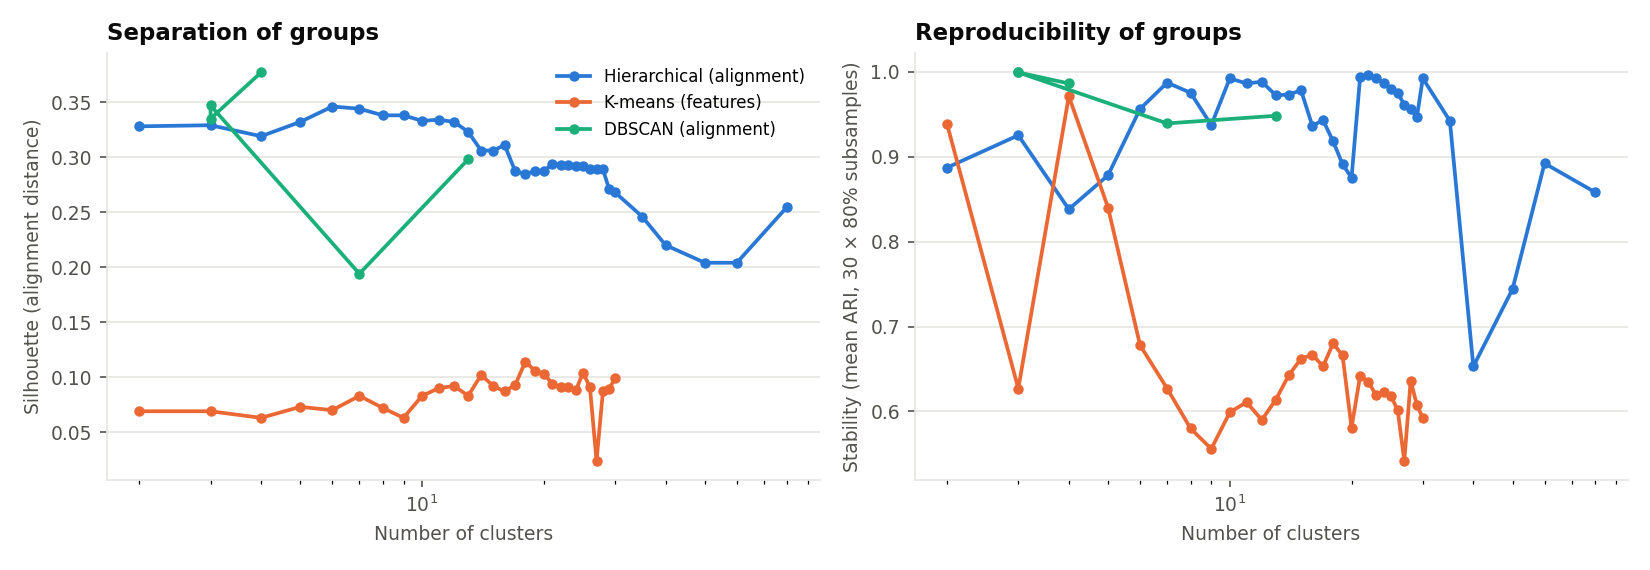

In [7]:
comp = pd.read_csv(C.CLUSTERING / "method_comparison.csv")
sel = json.loads((C.CLUSTERING / "clustering_selection.json").read_text())
display(comp.sort_values("silhouette_alignment", ascending=False).groupby("method").head(3))
display(Markdown(f"**Selected:** `{sel['final_method']}` with {int(sel['final_parameter'])} clusters; "
                 f"ARI vs k-means (same k) = {sel['ari_final_vs_kmeans_same_k']}, vs DBSCAN ε=0.5 = {sel['ari_final_vs_dbscan_eps0.5']}, "
                 f"vs 70%-identity groups = {sel['ari_final_vs_identity_group_70']} ({sel['n_identity_groups_70']} groups)."))
fig("f04_clustering_method_comparison.png", 900)

**Evaluation.**
* **Hierarchical clustering on alignment distance wins clearly.** Its best silhouette is about 0.34, it is highly
  stable, and the 7-cluster solution reproduces almost perfectly on subsamples.
* **K-means on composition/physicochemical features scores poorly** (silhouette ≈ 0.07–0.11 on alignment distance)
  and is unstable. It barely agrees with the homology clusters (ARI ≈ 0.08). Alignment-free composition features do
  not capture evolutionary relationships between these enzymes.
* **DBSCAN gets a high silhouette at ε = 0.7 only by labelling 25 proteins as noise**, which breaks the "assign
  every protein" requirement.
* **The 110 groups at 70% identity are not good ML clusters** (ARI ≈ 0.05 with the selected solution). They describe
  near-duplicates, which matters for data leakage, not family structure.
* **A silhouette of about 0.34 means moderate, not strong, structure.**

,subcluster,cluster,n_proteins,median_length,length_range,mean_within_identity_pct,coherence,with_gxsxg,top_gxsxg_variants,median_pI,n_specific_5mers,n_publications,top_publication_share,example_members
0,G1a,G1,165,277,211-434,42.6,coherent (mean identity >= 40%),165/165,GHSMG (101); GWSMG (42); GHSQG (8),7.75,0,55,10.1021/acscatal.5c03460 (42/165),"ISPETase, PET5, PET6, PET12, PLE628, PLE629, PpCutA, PE-H, PmC, Mors1"
1,G1b,G1,98,412,256-487,60.3,coherent (mean identity >= 40%),98/98,GHSMG (98); GTSAG (3); GGSTG (2),8.38,12,3,10.1021/acscatal.5c03460 (57/98),"407, 1628, 1611, 1625, 1603, 1538, 1465, 1621, 1617, 1534"
2,G2,G2,15,259,178-380,18.5,"heterogeneous (< 25%) - remainder group, not a family",15/15,GLSMG (3); GDSDG (2); GESEG (2),6.22,0,5,10.1038/s41467-022-35237-x (5/15),"PET46, 202, 204, 211, 214, 307, Est8_89, Est11_32, Ces19_14, Ces39_5"
3,G3,G3,9,228,186-238,41.8,coherent (mean identity >= 40%),9/9,GYSQG (9),6.70,1,11,10.1021/acssuschemeng.4c00060 (3/9),"FsC, HiC, PBATHRf, Sub1, FoCut5a, MRCUT1, TaC, DmC, RtC"
4,G4,G4,5,462,297-491,34.4,moderate (25-40%),5/5,GESAG (3); GQSAG (2); GDSPG (1),5.42,5,4,10.1038/s41467-022-35237-x (2/5),"BsEstB, 101, 102, Est18_23, Dkca1"
5,G5,G5,4,317,215-452,20.2,"heterogeneous (< 25%) - remainder group, not a family",3/4,GHSMG (2); GFSQG (1),5.86,0,4,10.3390/ijms23105612 (1/4),"EstB, Cbotu_EstA, Lip4_120, LipMRD9"
6,G6,G6,1,342,342-342,NaN,single protein,0/1,NaN,8.12,0,1,10.1016/j.procbio.2016.07.023 (1/1),CalB
7,G7,G7,1,352,352-352,NaN,single protein,1/1,GDSAG (1),6.91,0,1,10.1111/febs.70478 (1/1),TA21


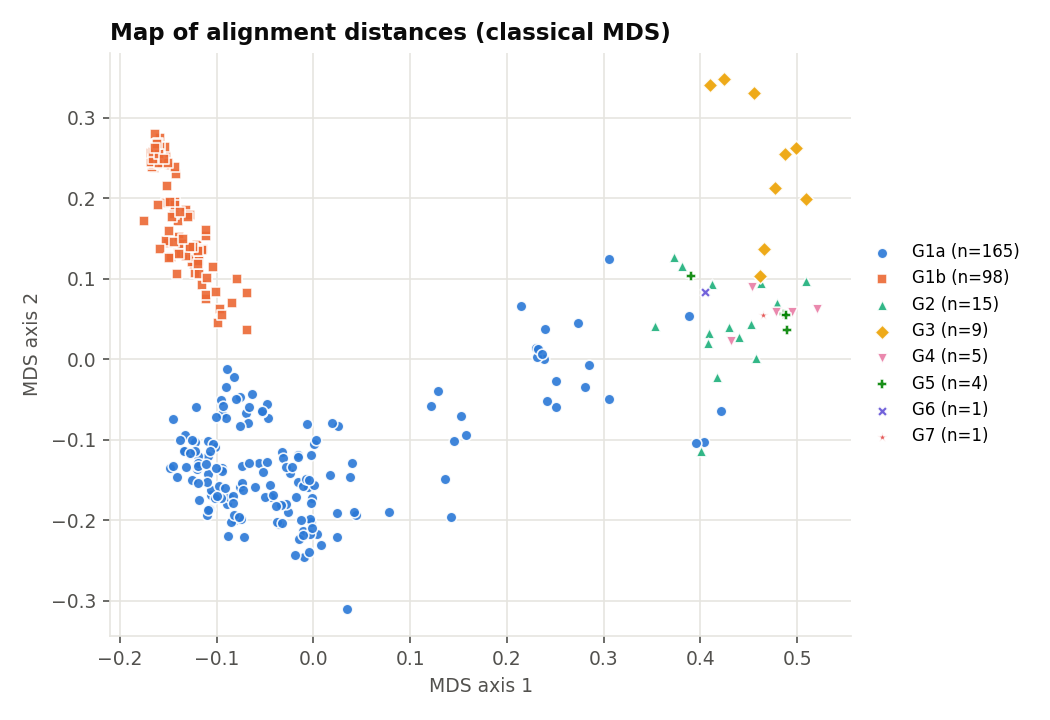

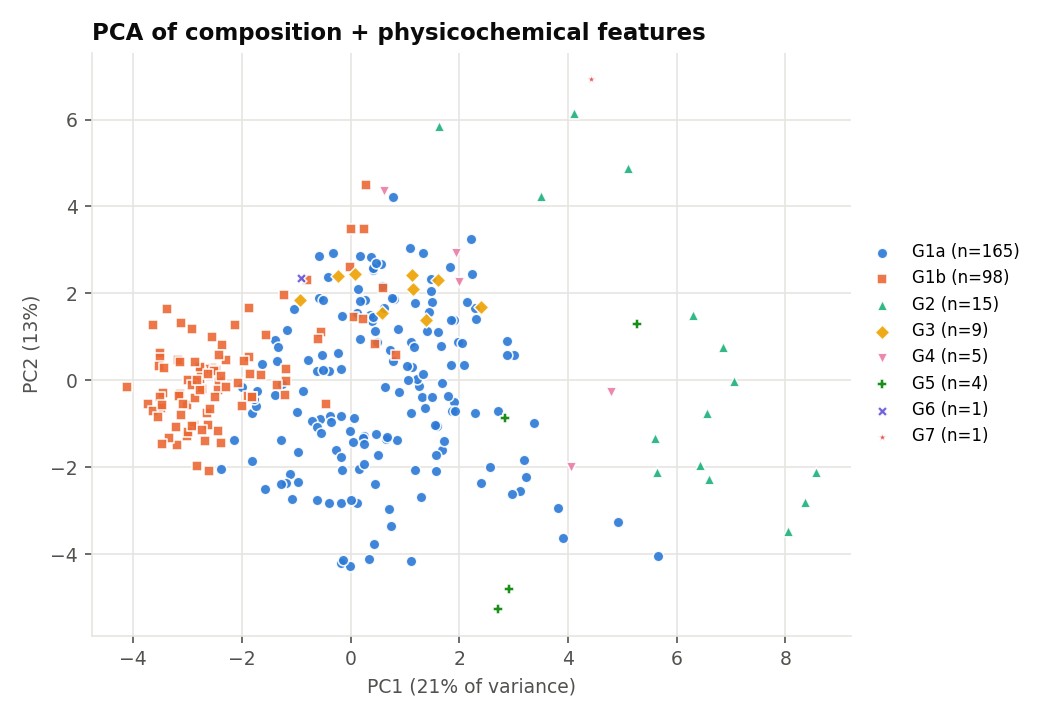

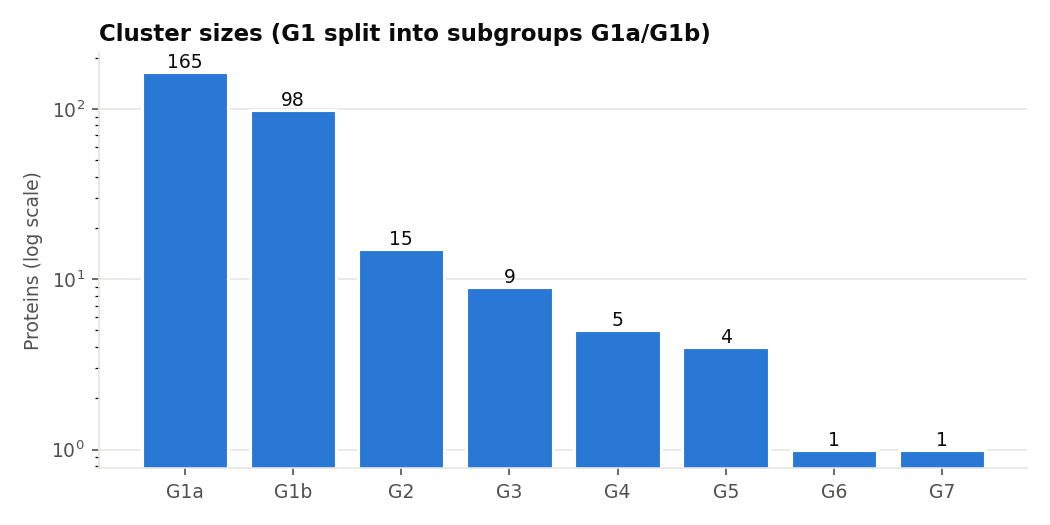

In [8]:
summ = pd.read_csv(C.CLUSTERING / "cluster_summary.csv")
display(summ)
fig("f06_mds_alignment.png"); fig("f05_pca_features.png"); fig("f08_cluster_sizes.png", 600)

### 6.1 Second level: structure inside G1

G1 holds 263 of 298 proteins. Average linkage only ever peels single outliers off it, but the MDS map shows two
clouds. We therefore compared four algorithms inside G1:
* average-linkage hierarchical clustering
* complete-linkage hierarchical clustering
* spectral clustering on the similarity matrix
* k-means on MDS coordinates

A split was accepted only if it was stable (ARI ≥ 0.95) and no subgroup held more than 90% of the members.

In [9]:
sub = pd.read_csv(C.CLUSTERING / "g1_subgroup_comparison.csv")
display(sub.sort_values(["stability_ari_mean", "silhouette_alignment"], ascending=False).head(8))
print("Selected:", sel["g1_subgroup_selected"])

,method,k,silhouette_alignment,stability_ari_mean,largest_subgroup_fraction,singletons,mean_within_identity
21,kmeans_on_mds,2,0.156,1.000,0.627,0,0.472
14,spectral_similarity,2,0.157,0.989,0.627,0,0.473
22,kmeans_on_mds,3,0.178,0.984,0.536,0,0.529
25,kmeans_on_mds,6,0.199,0.983,0.354,0,0.577
6,hierarchical_average,8,0.304,0.973,0.924,3,0.478
18,spectral_similarity,6,0.194,0.957,0.354,0,0.572
19,spectral_similarity,7,0.197,0.947,0.354,0,0.574
17,spectral_similarity,5,0.173,0.940,0.411,0,0.553


Selected: {'method': 'kmeans_on_mds', 'k': 2, 'silhouette_alignment': 0.156, 'stability_ari_mean': 1.0, 'largest_subgroup_fraction': 0.627, 'singletons': 0, 'mean_within_identity': 0.472}


**Interpretation.**
* **G1 divides perfectly reproducibly** into **G1a (165)** and **G1b (98)**, with ARI 1.0.
* **The separation is weak** (silhouette ≈ 0.16, below the 0.25 usually taken as "substantial structure").
  G1 is best seen as one lineage with a continuum of variants.
* **G1b is distinctive but narrowly sampled.** Its proteins are longer (median 412 aa), more similar to each other
  (mean 60% identity) and share 12 group-specific 5-mers. But they come from only three publications, mostly two
  large screening studies, so G1b may partly reflect *what was sampled*.

### 6.2 Motifs and cluster-specific sequence segments

We searched for 5-mers present in ≥ 80% of a group and ≤ 20% of all other proteins.

In [10]:
assign = pd.read_csv(C.CLUSTERING / "cluster_assignments.csv")
d = proteins.merge(assign[["protein_id", "cluster", "subcluster"]], on="protein_id")
for k in ["SMGGG", "GHSMG", "GWSMG", "GYSQG"]:
    has = d.sequence.str.contains(k)
    print(f"{k}: G1 {100*has[d.cluster=='G1'].mean():.1f}%  outside G1 {100*has[d.cluster!='G1'].mean():.1f}%  by group {d[has].subcluster.value_counts().to_dict()}")
display(pd.read_csv(C.CLUSTERING / "cluster_specific_kmers.csv"))

SMGGG: G1 93.2%  outside G1 2.9%  by group {'G1a': 147, 'G1b': 98, 'G2': 1}
GHSMG: G1 75.7%  outside G1 5.7%  by group {'G1a': 101, 'G1b': 98, 'G5': 2}
GWSMG: G1 16.0%  outside G1 0.0%  by group {'G1a': 42}
GYSQG: G1 0.0%  outside G1 25.7%  by group {'G3': 9}


,cluster,kmer,fraction_in_cluster,fraction_outside
0,G1b,GGGGA,0.908,0.100
1,G1b,YYPTD,0.918,0.095
2,G1b,PTDTS,0.878,0.105
3,G1b,YPTDT,0.888,0.100
4,G1b,LDYLT,0.857,0.150
5,G1b,PYQRG,0.806,0.075
6,G1b,YQRGP,0.837,0.115
7,G1b,PGYTA,0.806,0.130
8,G1b,GTQLL,0.837,0.030
9,G1b,RGTQL,0.837,0.020


**Interpretation (H1).**
* **296 of 298 proteins carry G-x-S-x-G**, and 263 of them form G1.
* **G1 is defined by an extended form of the motif.** The 5-mer SMGGG (as in G-H-S-M-G-G-G) occurs in 93% of G1
  and about 3% of other proteins.
* **G1a and G1b differ at the residue before the catalytic serine.** GWSMG (Trp) occurs only in G1a (42 proteins),
  while every G1b protein has GHSMG (His).
* **G3 is a small, coherent group with its own motif:** GYSQG, in all 9 members, which are about 228 aa long.

**H1 is supported:** most verified PET hydrolases belong to one motif-sharing sequence lineage.

## 7. Sequence-similarity network for Cytoscape

Nodes are proteins. An **edge** joins two proteins whose local alignment has **≥ 40% identity and covers ≥ 70% of both
sequences**. The threshold is defensible for two reasons:
* 40% identity over most of two ~300-aa proteins is well above the 25–35% "twilight zone" (Rost 1999), so edges indicate
  probable homology.
* The coverage rule stops short shared segments, such as signal peptides, from linking unrelated proteins.

This is a **sequence-similarity network, not a protein–protein interaction network.**

In [11]:
display(pd.read_csv(C.NETWORK / "edge_threshold_sensitivity.csv").query("min_coverage == 0.7"))
nodes, edges = pd.read_csv(C.NETWORK / "ssn_nodes.csv"), pd.read_csv(C.NETWORK / "ssn_edges.csv")
print(len(nodes), "nodes,", len(edges), "edges. Files: outputs/explorer/network/ssn_nodes.csv, ssn_edges.csv")
nodes.head()

,min_identity,min_coverage,edges,components,isolated_proteins,largest_component
1,0.30,0.7,15769,30,24,255
4,0.35,0.7,15349,37,28,244
7,0.40,0.7,14447,41,30,239
10,0.50,0.7,7867,49,40,236
13,0.60,0.7,2768,65,49,189
16,0.70,0.7,1049,118,89,62
19,0.80,0.7,737,179,144,38
22,0.90,0.7,166,234,207,22


298 nodes, 14447 edges. Files: outputs/explorer/network/ssn_nodes.csv, ssn_edges.csv


,id,protein_name,sequence_length,pet_label,label_confidence,cluster,identity_group_70,organism,taxonomy_id,organism_evidence,temperatures_tested_c,temperatures_with_activity_c,degree
0,1,ISPETase,290,PET-active (condition-dependent),high,G1,9,Ideonella sakaiensis,1547922,exact_sequence,20; 25; 30; 35; 37; 40; 45; 50; 55; 60; 72,20; 25; 30; 35; 37; 40; 45; 50; 55; 60; 72,147
1,2,PET5,310,PET-active,high,G1,106,Moraxella sp.; Oleispira antarctica,188908; 479,exact_sequence,25; 50,25; 50,139
2,3,PET6,298,PET-active,medium,G1,58,Vibrio gazogenes,687,exact_sequence,50,50,116
3,4,PET12,298,PET-active,high,G1,64,Polyangium brachysporum,413882,exact_sequence,30; 40; 50,30; 40; 50,148
4,5,PLE628,307,PET-active,high,G1,5,Marinobacter sp.,50741,exact_sequence,30,30,129


Import into Cytoscape:
1. **File → Import → Network from File** → `ssn_edges.csv` (source/target columns).
2. **File → Import → Table from File** → `ssn_nodes.csv` (key column `id`).
3. Colour nodes by `cluster`/`organism` and set edge width by `identity`.

## 8. Feature 1: sequence matching

A query is aligned locally against all 298 proteins.
* **Ranking:** a **length-normalised score**, raw / √(self-score of query × self-score of match). Raw scores
  alone would favour long proteins.
* **Per hit:** identity, query and match coverage, and a z-score against 25 shuffled copies of the query.

**Validation:**
* every protein retrieves itself (100%)
* a 10%-mutated IsPETase retrieves IsPETase
* shuffled sequences fall below the homology bands
* invalid input (DNA, ambiguity codes, multiple FASTA records) is rejected (tests in `tests/`)

In [12]:
from pet_explorer.sequence_matching import SequenceMatcher, hits_to_frame
import random
m = SequenceMatcher(proteins)
rng = random.Random(1); seq = list(proteins.sequence[0])
for i in rng.sample(range(len(seq)), len(seq)//10): seq[i] = rng.choice([a for a in C.STANDARD_AA if a != seq[i]])
header, q, hits = m.search("".join(seq))
display(hits_to_frame(hits, proteins).drop(columns="pet_evidence"))
print(hits[0].alignment_text[:420])

,rank,protein_id,protein_name,identity_pct,query_coverage_pct,target_coverage_pct,normalised_score,raw_score,shuffled_z,interpretation
0,1,1,ISPETase,90.0,100.0,100.0,0.878,1319.0,171.9,Near-identical to a characterised PET-active enzyme
1,2,259,APET-17,88.9,90.3,99.6,0.831,1197.0,161.7,Clear homolog of a characterised PET-active enzyme
2,3,197,PbsA,72.9,95.5,91.1,0.673,1042.0,144.6,Clear homolog of a characterised PET-active enzyme
3,4,15,RgPETase,73.2,90.0,89.0,0.644,973.0,116.9,Clear homolog of a characterised PET-active enzyme
4,5,416,ESM045,66.8,88.3,98.8,0.600,857.0,134.7,Clear homolog of a characterised PET-active enzyme


target            0 MNFPRASRLMQAAVLGGLMAVSAAATAQTNPYARGPNPTAASLEASAGPFTVRSFTVSRP
                  0 |.||.||||||.|...||||||||||||||||.|||||||||||||||.|||.|||||||
query             0 MGFPYASRLMQIALRVGLMAVSAAATAQTNPYSRGPNPTAASLEASAGLFTVVSFTVSRP

target           60 SGYGAGTVYYPTNAGGTVGAIAIVPGYTARQSSIKWWGPRLASHGFVVITIDTNSTLDQP
                 60 .|||||||.||||||||||||||||||||||||||||||||||||||.||.||||||.||
query         


In [13]:
loo = pd.read_csv(C.MATCHING / "leave_one_out_nearest_neighbour.csv")
print("Leave-one-out: closest OTHER reference protein for each of the 298 proteins")
loo.band.value_counts()

Leave-one-out: closest OTHER reference protein for each of the 298 proteins


band
Clear homolog of a characterised PET-active enzyme     175
Near-identical to a characterised PET-active enzyme     86
Twilight zone - possible distant homolog                29
No reliable similarity                                   8
Name: count, dtype: int64

**Interpretation.**
* **Most reference proteins have a near-identical or clear homolog elsewhere in the set.** This is the redundancy
  noted in the feasibility study.
* **A few have no reliable relative.** A query resembling those would get no useful match.
* **A match is always reported as a *promising candidate*.** Sequence similarity does not prove PET degradation.

## 9. Feature 3: experimental temperature analysis

We built a structured temperature dataset with one row per PET assay (temperature, pH, material, detection method,
outcome, DOI, cluster) and one row per measurement. Rules:
* The highest tested temperature is **not** the optimum.
* A *best tested temperature* is reported only inside a **comparable series**: same paper, metric, unit, pH,
  duration, material, enzyme loading and experiment context, with ≥ 3 temperatures.

optimum_status_category
one temperature                         115
two temperatures                         89
comparable series (>=3 temperatures)     80
no comparable series                      7
no temperature                            7
Name: count, dtype: int64

383 comparable series; best value at an edge of the tested range in 163


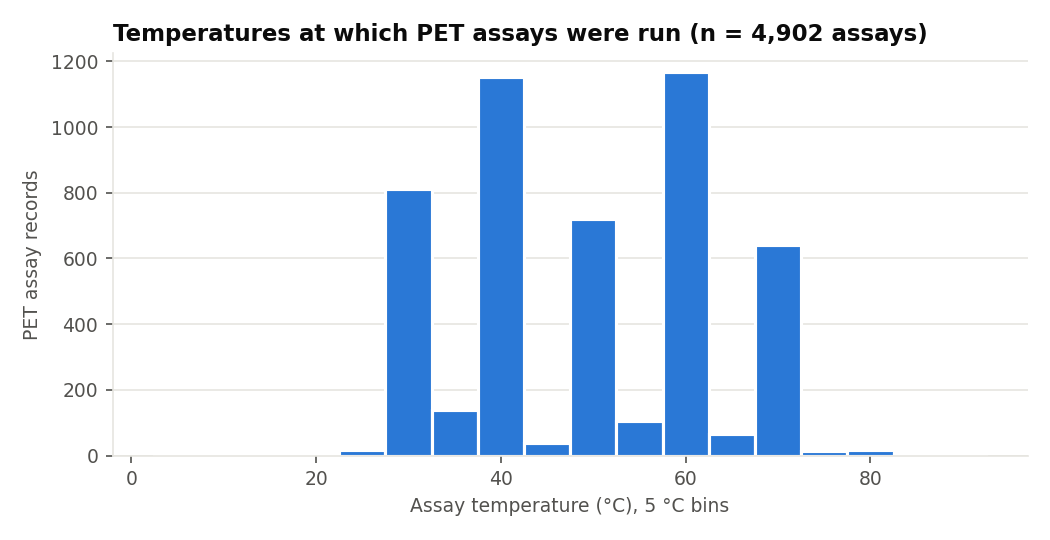

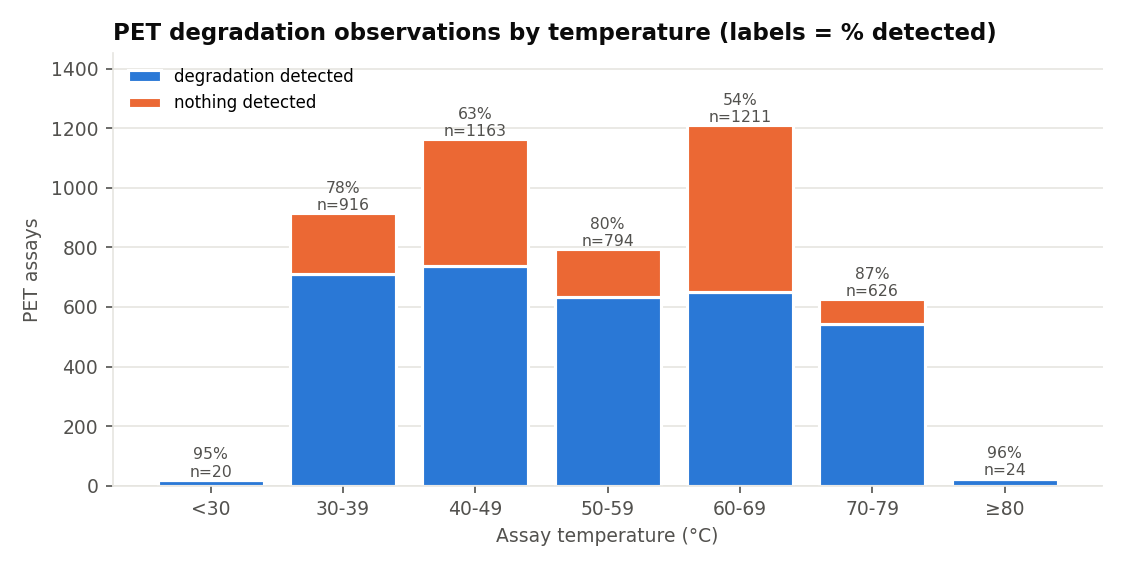

In [14]:
ts = pd.read_csv(C.TEMPERATURE / "protein_temperature_summary.csv")
display(ts.optimum_status_category.value_counts())
series = pd.read_csv(C.TEMPERATURE / "comparable_temperature_series.csv")
print(len(series), "comparable series; best value at an edge of the tested range in",
      int((series.best_at_edge != "interior").sum()))
fig("t01_tested_temperatures.png"); fig("t02_activity_by_temperature.png")

,subcluster,count,min,25%,50%,75%,max
0,G1a,472.0,4.0,40.0,50.0,60.00,85.0
1,G1b,140.0,30.0,30.0,40.0,50.00,70.0
2,G2,31.0,30.0,40.0,50.0,60.00,70.0
3,G3,24.0,30.0,37.0,50.0,56.25,85.0
4,G4,5.0,37.0,50.0,60.0,70.00,70.0
5,G5,4.0,30.0,37.5,40.0,42.50,50.0
6,G6,3.0,37.0,43.5,50.0,55.00,60.0
7,G7,2.0,60.0,62.5,65.0,67.50,70.0


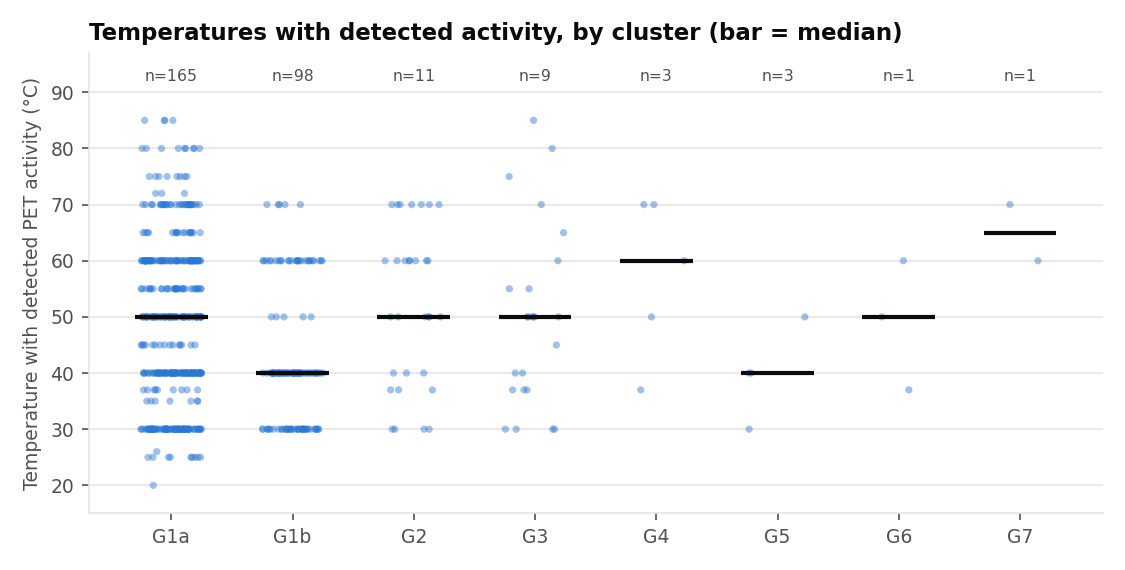

In [15]:
display(pd.read_csv(C.TEMPERATURE / "active_temperature_by_cluster.csv"))
fig("t03_active_temperature_by_cluster.png")

**Interpretation (H2).**
* **Two-thirds of proteins cannot have an optimum determined.** 115 proteins were tested at one temperature
  and 89 at only two.
* **Many series peak at the edge of their tested range**, so the true optimum may lie outside it.
* **Groups do differ in the temperatures where activity was detected** (e.g. G1a median 50 °C vs G1b 40 °C).
  But each group was tested in different studies with different temperature grids. 89% of G1b assays were run at
  exactly 40 °C or 60 °C, mostly in one screening study (DOI 10.1021/acscatal.5c03460).
* **H2 therefore cannot be confirmed:** the differences may reflect experimental design rather than enzyme
  thermostability.

**Valid cross-protein comparisons** exist only inside the two standardised screens, where one protocol was used for
many proteins.

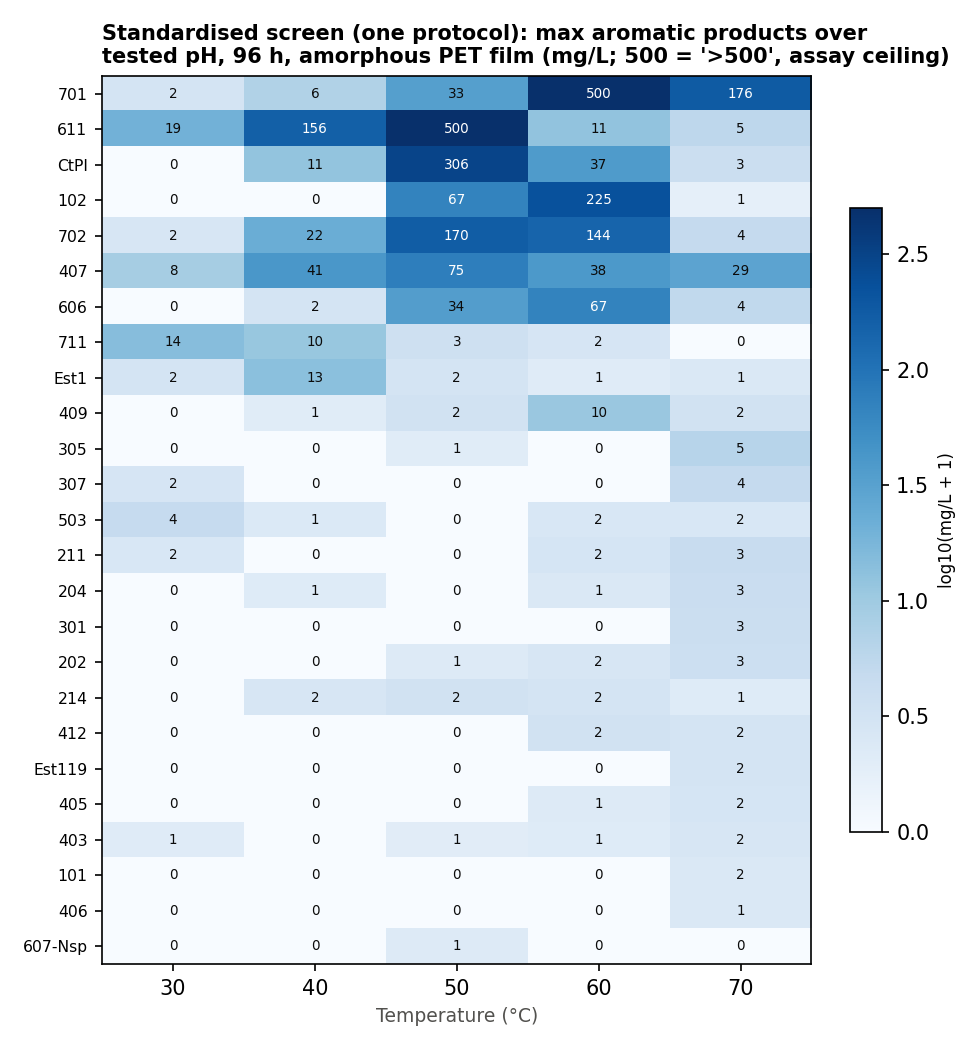

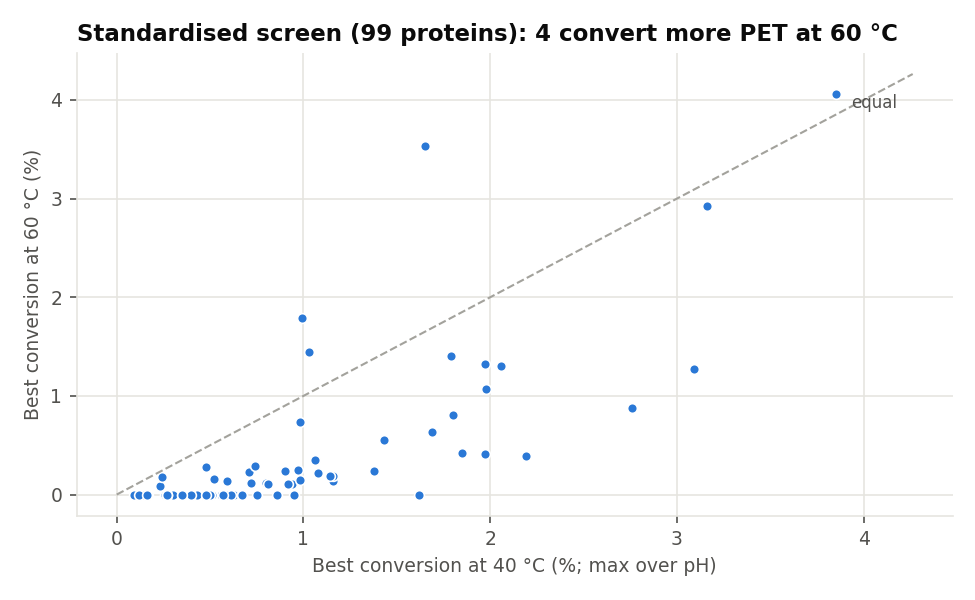

In [16]:
fig("t04_standardised_screen_d3.png", 550); fig("t05_standardised_screen_40_vs_60.png", 600)

In the 25-protein screen (DOI 10.1038/s41467-022-35237-x, Source Data Table D3), several enzymes give their highest
product release at 50–60 °C. Values of 500 mg/L hit the assay ceiling (">500"). In the 99-protein screen
(DOI 10.1021/acscatal.5c03460), most proteins converted more PET at 40 °C than at 60 °C under that protocol.

## 10. Feature 4: organism identification

Organisms come only from the provided files:
* **Exact sequence matches** (PlasticDB, degraders_list, UniProt)
* **Containment matches**: the PAZy sequence lies inside a database record or vice versa. Every such match covers
  ≥ 81% of the longer sequence, i.e. a precursor vs mature form.
* **PAZy curation text** ("cutinase from *Genus species*")

Expression hosts and organisms of *similar* sequences are never used. Unknown cases are reported as
"Unknown — insufficient evidence".

In [17]:
org = pd.read_csv(C.ORGANISMS / "protein_organisms.csv")
display(pd.read_csv(C.ORGANISMS / "organism_evidence_summary.csv"))
print("Tax ID available:", int(org.taxonomy_id.notna().sum()), "| databases disagree:", int(org.sources_disagree.sum()),
      "| uncultured/metagenomic:", int(org.uncultured_or_metagenomic.sum()))
display(org[org.sources_disagree][["protein_name", "organism", "evidence_detail"]])
org.organism.str.split("; ").explode().value_counts().head(12)

,evidence,proteins
0,none,139
1,contained_sequence,103
2,exact_sequence,56


Tax ID available: 159 | databases disagree: 4 | uncultured/metagenomic: 19


,protein_name,organism,evidence_detail
1,PET5,Moraxella sp.; Oleispira antarctica,PlasticDB: Oleispira antarctica (identical sequence) | PlasticDB: Moraxella ...
9,Mors1,Moraxella sp.; Oleispira antarctica; Olespira antarctica,PlasticDB: Moraxella sp. (identical sequence) | PlasticDB: Olespira antarcti...
27,PHL-7,Thermoanaerobacter sp.; Uncultured bacterium,PlasticDB: Uncultured bacterium (reference inside PAZy sequence; overlap 100...
197,DP038,Piscinibacter gummiphilus; Rhizobacter sp.,PlasticDB: Rhizobacter sp. (PAZy sequence inside reference; overlap 92% of l...


organism
Unknown — insufficient evidence    139
Uncultured bacterium                19
Micromonospora sp.                   7
Thermobifida fusca                   7
Streptomyces sp.                     5
Micromonosporales bacterium          3
Acidimicrobiales bacterium           3
Rhizobacter sp.                      3
Amycolatopsis sp.                    3
Ketobacter sp.                       2
Thermobifida cellulosilytica         2
Actinomycetes bacterium              2
Name: count, dtype: int64

**Interpretation.**
* **Organism coverage:** 159 of 298 proteins (53%) have an organism with sequence-level evidence. 139 remain unknown
  from these files.
* **Database disagreements:** some records conflict, e.g. PET5 has identical sequences filed under *Moraxella* sp.
  and *Oleispira antarctica*. Both are shown and flagged; neither is picked.
* **No isolate:** 19 proteins come from uncultured / metagenomic sources.

## 11. Conclusions, limitations and future work

**Conclusions**
1. **H1 supported.** 88% of verified PET-active enzymes form one sequence lineage (G1), sharing the catalytic-serine
   motif in an extended G-x-S-M-G-G-G form. A few small, distinct groups (e.g. G3, GYSQG) and outliers make up the rest.
2. **Choice of features matters.** Alignment-based clustering captures this structure. Composition-based k-means
   does not (ARI 0.08).
3. **G1 has a reproducible but weak internal split** (G1a/G1b), partly tied to how proteins were sampled.
4. **H2 not confirmed.** Temperature differences between groups are confounded by study design. Most proteins lack
   enough temperatures to define an optimum.

**Limitations**
* **No PET-inactive sequences**, so the system cannot predict PET degradation, only similarity to known degraders.
* **The data are redundant and literature-biased.** Large screening papers dominate some groups.
* **Assays are heterogeneous**: different units, methods, PET forms and conditions.
* **Organism known for only 53%** of proteins. There are no domain/family annotations (Pfam/InterPro).
* **Silhouette values are moderate (≤ 0.35).** Clusters are a useful summary, not sharp biological categories.

**Future work**
* Add experimentally confirmed inactive enzymes (with sequences) to enable supervised prediction.
* Enrich organisms and taxonomy via UniProt/NCBI accessions (`reference_accessions`, `accessions_in_pazy_notes`).
* Add Pfam/InterPro/ESTHER annotations to name the groups.
* Use protein language-model embeddings or structure-based features as alternatives to alignment.
* Extend the temperature analysis with thermostability data (e.g. melting temperatures).